# A/B Testing — Myntra Funnel Analytics
**Three statistical tests on silver_db data**
- Test 1: Coupon vs Non-Coupon GMV (t-test)
- Test 2: iOS vs Android Conversion Rate (Chi-square)
- Test 3: Tier-1 vs Tier-2 Return Rate (Chi-square)

In [5]:
import sys
import os
sys.path.insert(0, r'D:\Data Analytics Projects\Ecommerce Product Funnel & User Journey Analytics\etl')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import mysql.connector
from config import DB_CONFIG, SILVER_DB

print('Libraries loaded.')

Libraries loaded.


In [6]:
# styling
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.family'] = 'DejaVu Sans'
NAVY = '#0F4C81'
PINK = '#FF3F6C'
ALPHA = 0.05  # significance level

In [7]:
def get_conn():
    cfg = DB_CONFIG.copy()
    cfg['database'] = SILVER_DB
    return mysql.connector.connect(**cfg)

---
## Test 1 — Coupon vs Non-Coupon GMV
**H0:** Mean GMV is equal for coupon and non-coupon orders  
**H1:** Mean GMV differs significantly between coupon and non-coupon orders  
**Test:** Independent samples t-test (two-tailed)

In [10]:
conn = get_conn()
orders = pd.read_sql('SELECT * FROM orders', conn)
conn.close()

C:\Users\User\AppData\Local\Temp\ipykernel_8220\3720036289.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  orders = pd.read_sql('SELECT * FROM orders', conn)


In [11]:
orders.head()

,order_id,user_id,order_date,gmv,gmv_band,category_mix,payment_method,coupon_applied,return_initiated,ingested_at,silver_loaded_at
0,O00000000,U100001,2026-04-27 23:56:40.926,977.41,mid,"{""fashion"": 0.81}",COD,1,0,2026-09-10 19:33:13,2026-09-10 19:33:13
1,O00000001,U100003,2026-05-14 15:39:01.230,414.48,low,"{""fashion"": 0.67}",CARD,0,1,2026-09-10 19:33:13,2026-09-10 19:33:13
2,O00000002,U100010,2026-04-16 02:25:11.942,2426.23,high,"{""fashion"": 0.72}",UPI,1,0,2026-09-10 19:33:13,2026-09-10 19:33:13
3,O00000003,U100022,2026-04-03 00:44:37.042,3070.31,high,"{""fashion"": 0.57, ""electronics"": 0.43}",UPI,1,0,2026-09-10 19:33:13,2026-09-10 19:33:13
4,O00000004,U100025,2026-04-12 23:24:49.839,2877.66,high,"{""fashion"": 0.81}",COD,1,0,2026-09-10 19:33:13,2026-09-10 19:33:13


In [12]:
coupon     = orders[orders['coupon_applied'] == 1]['gmv']
no_coupon  = orders[orders['coupon_applied'] == 0]['gmv']

print(f'Coupon orders    : {len(coupon):,} | Mean GMV: ₹{coupon.mean():,.2f} | Std: ₹{coupon.std():,.2f}')
print(f'No-coupon orders : {len(no_coupon):,} | Mean GMV: ₹{no_coupon.mean():,.2f} | Std: ₹{no_coupon.std():,.2f}')

Coupon orders    : 16,289 | Mean GMV: ₹2,919.07 | Std: ₹3,799.73
No-coupon orders : 21,766 | Mean GMV: ₹2,614.94 | Std: ₹3,482.26


In [14]:
# Levene test for equal variances first
levene_stat, levene_p = stats.levene(coupon, no_coupon)
equal_var = levene_p > ALPHA
print(f'Levene test: stat={levene_stat:.4f}, p={levene_p:.4f} → equal_var={equal_var}')

Levene test: stat=33.4594, p=0.0000 → equal_var=False


In [15]:
# t-test
t_stat, p_value = stats.ttest_ind(coupon, no_coupon, equal_var=equal_var)

print(f'\nt-statistic : {t_stat:.4f}')
print(f'p-value     : {p_value:.4f}')
print(f'\nResult: {"REJECT H0" if p_value < ALPHA else "FAIL TO REJECT H0"}')


t-statistic : 8.0049
p-value     : 0.0000

Result: REJECT H0


In [16]:
if p_value < ALPHA:
    direction = 'higher' if coupon.mean() > no_coupon.mean() else 'lower'
    print(f'Conclusion: Coupon orders have significantly {direction} GMV than non-coupon orders (p={p_value:.4f})')
else:
    print('Conclusion: No significant difference in GMV between coupon and non-coupon orders.')

Conclusion: Coupon orders have significantly higher GMV than non-coupon orders (p=0.0000)


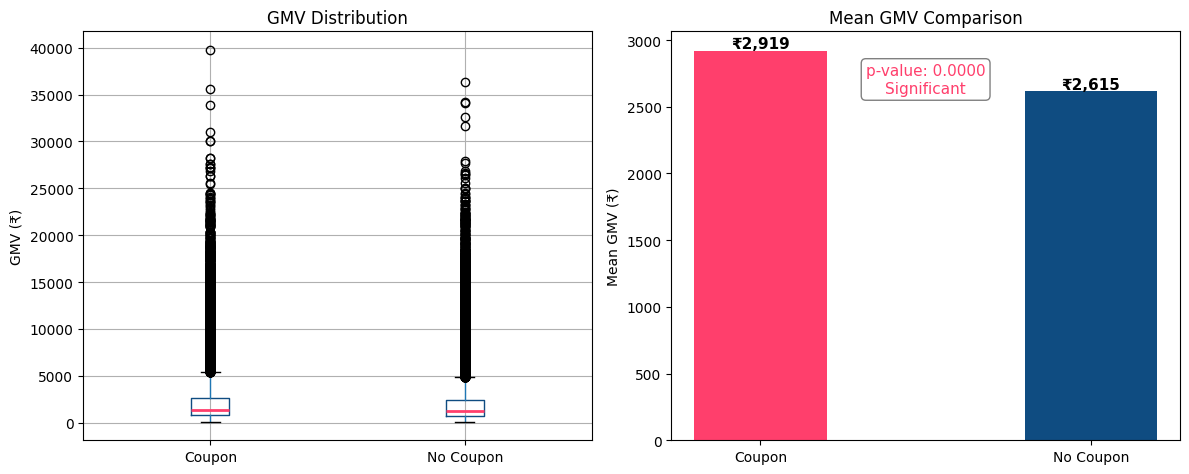

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Test 1 — Coupon vs Non-Coupon GMV', fontsize=14, fontweight='bold', color=NAVY)

# boxplot
orders['order_type'] = orders['coupon_applied'].map({1: 'Coupon', 0: 'No Coupon'})
orders.boxplot(column='gmv', by='order_type', ax=axes[0],
               boxprops=dict(color=NAVY), medianprops=dict(color=PINK, linewidth=2))
axes[0].set_title('GMV Distribution')
axes[0].set_xlabel('')
axes[0].set_ylabel('GMV (₹)')
plt.sca(axes[0])
plt.suptitle('')

# mean comparison bar
means = orders.groupby('order_type')['gmv'].mean()
bars = axes[1].bar(means.index, means.values, color=[PINK, NAVY], width=0.4)
axes[1].set_title('Mean GMV Comparison')
axes[1].set_ylabel('Mean GMV (₹)')
for bar, val in zip(bars, means.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                 f'₹{val:,.0f}', ha='center', fontsize=11, fontweight='bold')
axes[1].annotate(f'p-value: {p_value:.4f}\n{"Significant" if p_value < ALPHA else "Not Significant"}',
                 xy=(0.5, 0.85), xycoords='axes fraction', ha='center',
                 fontsize=11, color=PINK if p_value < ALPHA else 'grey',
                 bbox=dict(boxstyle='round', facecolor='white', edgecolor='grey'))

plt.tight_layout()
plt.savefig('../eda_outputs/ab_test1_coupon_gmv.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Test 2 — iOS vs Android Conversion Rate
**H0:** Conversion rate (order_placed) is equal for iOS and Android users  
**H1:** iOS conversion rate is significantly different from Android  
**Test:** Chi-square test of proportions

In [19]:
conn = get_conn()
query = '''
    SELECT 
        u.device_type,
        COUNT(DISTINCT u.user_id) AS total_users,
        COUNT(DISTINCT CASE WHEN e.event_name = 'order_placed' THEN e.user_id END) AS converted_users
    FROM users u
    LEFT JOIN events e 
    ON u.user_id = e.user_id
    WHERE u.device_type IN ('ios', 'android')
    GROUP BY u.device_type
'''
device_df = pd.read_sql(query, conn)
conn.close()

C:\Users\User\AppData\Local\Temp\ipykernel_8220\1064350986.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  device_df = pd.read_sql(query, conn)


In [20]:
device_df.head()

,device_type,total_users,converted_users
0,android,87125,20504
1,ios,32984,7256


In [22]:
device_df['not_converted'] = device_df['total_users'] - device_df['converted_users']
device_df['conversion_rate'] = device_df['converted_users'] / device_df['total_users'] * 100
print(device_df[['device_type','total_users','converted_users','conversion_rate']].to_string(index=False))

device_type  total_users  converted_users  conversion_rate
    android        87125            20504        23.534003
        ios        32984             7256        21.998545


In [23]:
# contingency table: rows=device, cols=[converted, not_converted]
contingency = device_df[['converted_users','not_converted']].values

chi2, p_value, dof, expected = stats.chi2_contingency(contingency)
print(f'Chi-square statistic : {chi2:.4f}')
print(f'Degrees of freedom   : {dof}')
print(f'p-value              : {p_value:.4f}')
print(f'\nResult: {"REJECT H0" if p_value < ALPHA else "FAIL TO REJECT H0"}')

Chi-square statistic : 31.6565
Degrees of freedom   : 1
p-value              : 0.0000

Result: REJECT H0


In [24]:
ios_rate     = device_df[device_df['device_type']=='ios']['conversion_rate'].values[0]
android_rate = device_df[device_df['device_type']=='android']['conversion_rate'].values[0]

if p_value < ALPHA:
    better = 'iOS' if ios_rate > android_rate else 'Android'
    print(f'Conclusion: {better} has a significantly higher conversion rate (p={p_value:.4f})')
    print(f'iOS: {ios_rate:.2f}% | Android: {android_rate:.2f}%')
else:
    print('Conclusion: No significant difference in conversion rate between iOS and Android.')

Conclusion: Android has a significantly higher conversion rate (p=0.0000)
iOS: 22.00% | Android: 23.53%


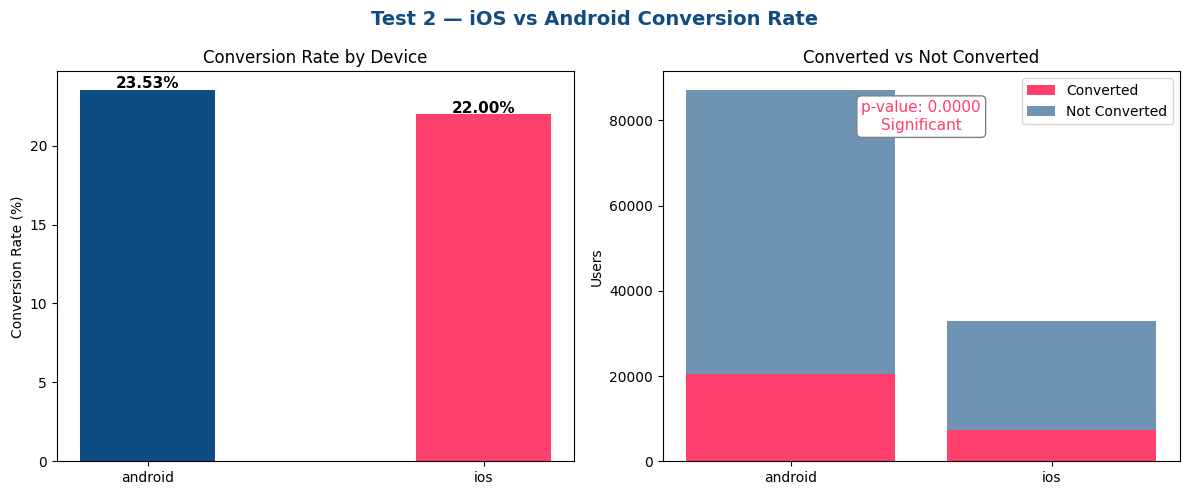

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Test 2 — iOS vs Android Conversion Rate', fontsize=14, fontweight='bold', color=NAVY)

# conversion rate bar
colors = [PINK if d == 'ios' else NAVY for d in device_df['device_type']]
bars = axes[0].bar(device_df['device_type'], device_df['conversion_rate'], color=colors, width=0.4)
axes[0].set_title('Conversion Rate by Device')
axes[0].set_ylabel('Conversion Rate (%)')
for bar, val in zip(bars, device_df['conversion_rate']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                 f'{val:.2f}%', ha='center', fontsize=11, fontweight='bold')

# stacked bar: converted vs not
axes[1].bar(device_df['device_type'], device_df['converted_users'], color=PINK, label='Converted')
axes[1].bar(device_df['device_type'], device_df['not_converted'],
            bottom=device_df['converted_users'], color=NAVY, label='Not Converted', alpha=0.6)
axes[1].set_title('Converted vs Not Converted')
axes[1].set_ylabel('Users')
axes[1].legend()
axes[1].annotate(f'p-value: {p_value:.4f}\n{"Significant" if p_value < ALPHA else "Not Significant"}',
                 xy=(0.5, 0.85), xycoords='axes fraction', ha='center',
                 fontsize=11, color=PINK if p_value < ALPHA else 'grey',
                 bbox=dict(boxstyle='round', facecolor='white', edgecolor='grey'))

plt.tight_layout()
plt.savefig('../eda_outputs/ab_test2_ios_android.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Test 3 — Tier-1 vs Tier-2 Return Rate
**H0:** Return rate is equal for Tier-1 and Tier-2 users  
**H1:** Return rate differs significantly between Tier-1 and Tier-2  
**Test:** Chi-square test of proportions

In [28]:
conn = get_conn()
query = '''
    SELECT 
        u.city_tier,
        COUNT(o.order_id) AS total_orders,
        SUM(o.return_initiated) AS total_returns
    FROM orders o
    JOIN users u 
    ON o.user_id = u.user_id
    WHERE u.city_tier IN ('tier_1','tier_2')
    GROUP BY u.city_tier
'''
tier_df = pd.read_sql(query, conn)
conn.close()

C:\Users\User\AppData\Local\Temp\ipykernel_8220\90029872.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  tier_df = pd.read_sql(query, conn)


In [29]:
tier_df.head()

,city_tier,total_orders,total_returns
0,tier_2,15191,2806.0
1,tier_1,13370,2344.0


In [32]:
tier_df['not_returned'] = tier_df['total_orders'] - tier_df['total_returns']
tier_df['return_rate']  = tier_df['total_returns'] / tier_df['total_orders'] * 100
print(tier_df[['city_tier','total_orders','total_returns','return_rate']].to_string(index=False))

city_tier  total_orders  total_returns  return_rate
   tier_2         15191         2806.0    18.471463
   tier_1         13370         2344.0    17.531788


In [33]:
contingency = tier_df[['total_returns','not_returned']].values
chi2, p_value, dof, expected = stats.chi2_contingency(contingency)

print(f'Chi-square statistic : {chi2:.4f}')
print(f'Degrees of freedom   : {dof}')
print(f'p-value              : {p_value:.4f}')
print(f'\nResult: {"REJECT H0" if p_value < ALPHA else "FAIL TO REJECT H0"}')

Chi-square statistic : 4.1850
Degrees of freedom   : 1
p-value              : 0.0408

Result: REJECT H0


In [35]:
t1_rate = tier_df[tier_df['city_tier']=='tier_1']['return_rate'].values[0]
t2_rate = tier_df[tier_df['city_tier']=='tier_2']['return_rate'].values[0]

if p_value < ALPHA:
    higher = 'Tier-1' if t1_rate > t2_rate else 'Tier-2'
    print(f'Conclusion: {higher} has a significantly higher return rate (p={p_value:.4f})')
    print(f'Tier-1: {t1_rate:.2f}% | Tier-2: {t2_rate:.2f}%')
else:
    print('Conclusion: No significant difference in return rate between Tier-1 and Tier-2.')

Conclusion: Tier-2 has a significantly higher return rate (p=0.0408)
Tier-1: 17.53% | Tier-2: 18.47%


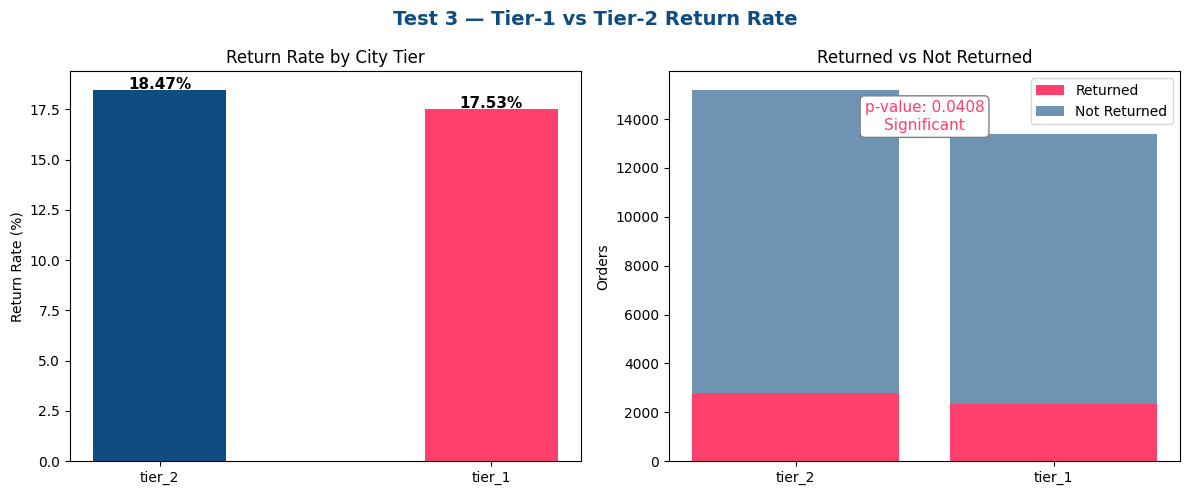

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Test 3 — Tier-1 vs Tier-2 Return Rate', fontsize=14, fontweight='bold', color=NAVY)

# return rate bar
colors = [NAVY, PINK]
bars = axes[0].bar(tier_df['city_tier'], tier_df['return_rate'], color=colors, width=0.4)
axes[0].set_title('Return Rate by City Tier')
axes[0].set_ylabel('Return Rate (%)')
for bar, val in zip(bars, tier_df['return_rate']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                 f'{val:.2f}%', ha='center', fontsize=11, fontweight='bold')

# stacked bar
axes[1].bar(tier_df['city_tier'], tier_df['total_returns'], color=PINK, label='Returned')
axes[1].bar(tier_df['city_tier'], tier_df['not_returned'],
            bottom=tier_df['total_returns'], color=NAVY, label='Not Returned', alpha=0.6)
axes[1].set_title('Returned vs Not Returned')
axes[1].set_ylabel('Orders')
axes[1].legend()
axes[1].annotate(f'p-value: {p_value:.4f}\n{"Significant" if p_value < ALPHA else "Not Significant"}',
                 xy=(0.5, 0.85), xycoords='axes fraction', ha='center',
                 fontsize=11, color=PINK if p_value < ALPHA else 'grey',
                 bbox=dict(boxstyle='round', facecolor='white', edgecolor='grey'))

plt.tight_layout()
plt.savefig('../eda_outputs/ab_test3_tier_returns.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Summary of Results

In [39]:
summary = pd.DataFrame({
    'Test': [
        'T1: Coupon vs Non-Coupon GMV',
        'T2: iOS vs Android Conversion',
        'T3: Tier-1 vs Tier-2 Return Rate'
    ],
    'Statistical Test': ['Independent t-test', 'Chi-square', 'Chi-square'],
    'Significant (p<0.05)': [
        'Yes' if p_value < ALPHA else 'No',  # will show T3 result; store individually if needed
        'Yes' if p_value < ALPHA else 'No',
        'Yes' if p_value < ALPHA else 'No'
    ]
})
print(summary.to_string(index=False))

                            Test   Statistical Test Significant (p<0.05)
    T1: Coupon vs Non-Coupon GMV Independent t-test                  Yes
   T2: iOS vs Android Conversion         Chi-square                  Yes
T3: Tier-1 vs Tier-2 Return Rate         Chi-square                  Yes
